In [1]:
import json
import re
import numpy as np
import os
import sys
from collections import defaultdict
from sklearn.cluster import AgglomerativeClustering
from sentence_transformers import SentenceTransformer
from sentence_transformers.models import StaticEmbedding
from postprocessing import postprocessing
import math

c:\Users\ASUS\.conda\envs\env_py39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\ASUS\.conda\envs\env_py39\lib\site-packages\spacy\util.py:910: UserWarning: [W095] Model 'en_core_web_lg' (3.4.1) was trained with spaCy v3.4.0 and may not be 100% compatible with the current version (3.7.5). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


In [2]:
DISTANCE_THRESHOLD = 0.12

In [3]:
def load_json(path):
    if not os.path.exists(path):
        print(f"Lỗi: Không tìm thấy file tại {path}")
        return {}
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)
    

def save_json(data, file_path):
    with open(file_path, 'w', encoding='utf-8') as file:
        json.dump(data, file, ensure_ascii=False, indent=4)
        
        
def extract_references(long_answer):
    if not long_answer:
        return []
    return re.findall(r"\[([^\]]+)\]", long_answer)

def cluster_cohesion(embeddings):
    if len(embeddings) <= 1:
        return 0
    centroid = embeddings.mean(axis=0)
    dists = np.linalg.norm(embeddings - centroid, axis=1)
    return dists.mean()

import json
import numpy as np

def save_embedding_cache(cache, file_path):
    # Chuyển đổi tất cả ndarray sang list để JSON có thể serialize được
    cache_to_save = {k: v.tolist() if isinstance(v, np.ndarray) else v 
                     for k, v in cache.items()}
    
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(cache_to_save, f, ensure_ascii=False, indent=4)

# Khi load lại, bạn cũng cần convert ngược từ list sang numpy array
def load_embedding_cache(file_path):
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            cached_data = json.load(f)
        return {k: np.array(v) for k, v in cached_data.items()}
    except FileNotFoundError:
        return {}

In [ ]:
def collect_candidates(cluster_file, mapping_data):
    raw_data = load_json(cluster_file)
    processed_data = {}

    for qidx, clusters in raw_data.items():
        cand_list = []
        for cid, cluster in clusters.items():
            if "llm" not in cluster:
                continue

            ans = cluster["llm"].get("short_answer", "").strip().lower()
            long_answer = cluster["llm"].get("long_answer", "")
            context = cluster.get("context", "").lower()
            
            if not ans or ans == "insufficient information":
                continue

            if ans in mapping_data:
                norm_ans = mapping_data[ans]
            else:
                norm_ans = postprocessing(ans)
                norm_ans = mapping_data.get(norm_ans, norm_ans)
            
            # norm_ans= postprocessing(ans)
            
            raw_sources = extract_references(long_answer)
            sources = list(set(raw_sources))
            has_wiki = any("WIKI" in s for s in sources)
            has_gg = any("GG" in s for s in sources)

            cand_list.append({
                "text": norm_ans,
                "long_answer": long_answer,
                "context": context,
                "sources": sources,
                "has_wiki": has_wiki,
                "has_gg": has_gg
            })
        
        # không phân cụm
        # processed_data[qidx] = cand_list if len(cand_list) >= 2 else None
       
        processed_data[qidx] = cand_list if len(cand_list) >= 1 else None
        
    return processed_data

In [ ]:
# def collect_candidates(cluster_file, mapping_data):
#     raw_data = load_json(cluster_file)
#     processed_data = {}

#     for qidx, clusters in raw_data.items():
#         # Dùng dict để group theo norm_ans: {norm_ans: {data}}
#         temp_grouped = {}

#         for cid, cluster in clusters.items():
#             if "llm" not in cluster:
#                 continue

#             ans = cluster["llm"].get("short_answer", "").strip().lower()
#             long_answer = cluster["llm"].get("long_answer", "")
#             context = cluster.get("context", "").lower()
            
#             if not ans or ans == "insufficient information":
#                 continue

#             # --- Logic chuẩn hóa (giữ nguyên của bạn) ---
#             # if ans in mapping_data:
#             #     norm_ans = mapping_data[ans]
#             # else:
#             #     norm_ans = postprocessing(ans)
#             #     norm_ans = mapping_data.get(norm_ans, norm_ans)
#             norm_ans = postprocessing(ans)
#             # --- Xử lý sources ---
#             raw_sources = extract_references(long_answer)
#             current_sources = set(raw_sources)

#             if norm_ans not in temp_grouped:
#                 # Nếu là lần đầu gặp candidate này trong qidx này
#                 temp_grouped[norm_ans] = {
#                     "cid": cid,  # Lấy cid đầu tiên
#                     "text": norm_ans,
#                     "long_answer": long_answer,
#                     "context": context,
#                     "sources": current_sources, # Dùng set để gộp không trùng
#                     "has_wiki": any("WIKI" in s for s in current_sources),
#                     "has_gg": any("GG" in s for s in current_sources)
#                 }
#             else:
#                 # Nếu đã tồn tại, tiến hành gộp (update)
#                 # 1. Cộng dồn sources (union set)
#                 temp_grouped[norm_ans]["sources"].update(current_sources)
                
#                 # 2. Update lại flags has_wiki/has_gg nếu source mới có chứa
#                 if any("WIKI" in s for s in current_sources):
#                     temp_grouped[norm_ans]["has_wiki"] = True
#                 if any("GG" in s for s in current_sources):
#                     temp_grouped[norm_ans]["has_gg"] = True
                
#                 # Lưu ý: cid, long_answer, context giữ nguyên của cái đầu tiên

#         # Chuyển dict tạm về list và convert set sources về list để JSON serializable
#         final_cand_list = []
#         for cand in temp_grouped.values():
#             cand["sources"] = list(cand["sources"])
#             final_cand_list.append(cand)
        
#         processed_data[qidx] = final_cand_list if len(final_cand_list) >= 1 else None
        
#     return processed_data

# Công thức 3 Harmonic-based balance
## Công thức 3A

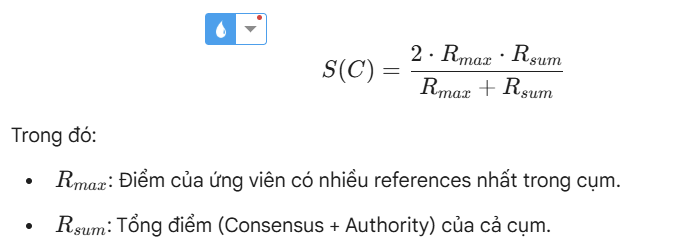

In [57]:
# công thức 3a 
MIN_SCORE_THRESHOLD = 3.0 

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0, "clusters": [], "candidates": None
            }
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                all_sources = set()
                max_ref_in_cluster = 0
                has_expert = False
                # Danh sách số refer (ri) của từng candidate trong cụm
                individual_ref_counts = 0
                for i in indices:
                    candidate = cand_list[i]
                    ref_count = len(candidate["sources"])
                    all_sources.update(candidate["sources"])
                    
                    # Tìm R_max: Số ref lớn nhất của một cá nhân trong cụm
                    if ref_count > max_ref_in_cluster:
                        max_ref_in_cluster = ref_count
                    
                    if ref_count >= 5:
                        has_expert = True
                
                    individual_ref_counts += ref_count
                evidence_cnt = len(indices)
                unique_src_cnt = len(all_sources)
                
                # --- TÍNH TOÁN THEO CÔNG THỨC HARMONIC ---
                
                # 1. R_max: Điểm của candidate mạnh nhất 
                r_max = max_ref_in_cluster
                # if has_expert:
                #     r_max += BONUS_EXPERT
                                
                r_sum = individual_ref_counts

                # 3. Tính Harmonic Mean S(C)
                # Tránh chia cho 0 nếu cả hai bằng 0
                if (r_max + r_sum) > 0:
                    c_score = (2 * r_max * r_sum) / (r_max + r_sum)
                else:
                    c_score = 0
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": evidence_cnt,
                    "unique_source": unique_src_cnt,
                    "has_expert": has_expert,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT DỰA TRÊN HARMONIC SCORE
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ (ABSTAIN)
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            # ... (Phần cache_miss giữ nguyên)
            continue
        
        # 4. CHỌN ỨNG VIÊN TRONG CỤM (Người có nhiều sources nhất)
        chosen_indices = best_cluster_info["indices"]
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 2),
            "debug_details": f"Rmax:{max_ref_in_cluster}, Rsum:{round(best_cluster_info['cluster_score'], 2)}, Expert:{best_cluster_info['has_expert']}"
        }

    return fused_results, list(list_id_miss)

## Công thức 3B: Thay R_sum trong 3 thành N_c


In [195]:
# =========================
# CONFIG SCORING - HARMONIC BALANCE
# ========================= 
MIN_SCORE_THRESHOLD = 1.5

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0, "clusters": [], "candidates": None
            }
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                all_sources = set()
                max_ref_in_cluster = 0
                has_expert = False
                
                for i in indices:
                    candidate = cand_list[i]
                    ref_count = len(candidate["sources"])
                    all_sources.update(candidate["sources"])
                    
                    # Tìm R_max: Số ref lớn nhất của một cá nhân trong cụm
                    if ref_count > max_ref_in_cluster:
                        max_ref_in_cluster = ref_count
                    
                 
                evidence_cnt = len(indices)
                unique_src_cnt = len(all_sources)
                
                # --- TÍNH TOÁN THEO CÔNG THỨC HARMONIC ---
                
                # 1. R_max: Điểm của candidate mạnh nhất 
                r_max = max_ref_in_cluster
             
                
                # 2. R_sum: Thay R_sum bằng N_c
                r_sum = evidence_cnt

                # 3. Tính Harmonic Mean S(C)
                # Tránh chia cho 0 nếu cả hai bằng 0
                if (r_max + r_sum) > 0:
                    c_score = (2 * r_max * r_sum) / (r_max + r_sum)
                else:
                    c_score = 0
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": evidence_cnt,
                    "unique_source": unique_src_cnt,
                    "has_expert": has_expert,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT DỰA TRÊN HARMONIC SCORE
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ (ABSTAIN)
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            # ... (Phần cache_miss giữ nguyên)
            continue
        
        # 4. CHỌN ỨNG VIÊN TRONG CỤM (Người có nhiều sources nhất)
        chosen_indices = best_cluster_info["indices"]
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 2),
            "debug_details": f"Rmax:{max_ref_in_cluster}, Rsum:{round(best_cluster_info['cluster_score'], 2)}, Expert:{best_cluster_info['has_expert']}"
        }

    return fused_results, list(list_id_miss)

# CÔNG THỨC 1: LOG COMBINATION

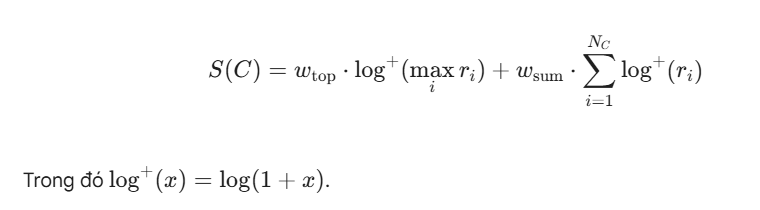

In [53]:
import math

# =========================
# CONFIG SCORING - LOG COMBINATION
# =========================
W_TOP = 0.6    # Trọng số cho candidate mạnh nhất (theo gợi ý trong ảnh)
W_SUM = 0.4    # Trọng số cho tổng số refer
MIN_SCORE_THRESHOLD = 1.5  # Ngưỡng tối thiểu để chọn cụm

def log_plus(x):
    """Hàm log+(x) = log(1 + x) để làm mềm ảnh hưởng của outlier."""
    return math.log(1 + x)

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0, "clusters": [], "candidates": None
            }
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                individual_ref_counts = []
                for i in indices:
                    ref_count = len(cand_list[i]["sources"])
                    individual_ref_counts.append(ref_count)
                
                # --- TÍNH TOÁN THEO CÔNG THỨC LOG COMBINATION ---
                
                # 1. Term log+(max r_i): Ưu tiên cụm có một candidate rất mạnh
                max_ri = max(individual_ref_counts)
                term_top = log_plus(max_ri)
                
                # 2. Term sum log+(r_i): Ưu tiên cụm có tổng lượng refer lớn
                term_sum = sum(log_plus(ri) for ri in individual_ref_counts)
                
                # 3. Kết hợp với trọng số w_top và w_sum
                c_score = (W_TOP * term_top) + (W_SUM * term_sum)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": len(indices),
                    "max_ri": max_ri,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT DỰA TRÊN LOG SCORE
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ (ABSTAIN)
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)

            continue
        
        # 4. CHỌN ỨNG VIÊN TRONG CỤM (Người có nhiều sources nhất)
        chosen_indices = best_cluster_info["indices"]
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4),
            "debug_details": f"Max_ri:{best_cluster_info['max_ri']}, NC:{best_cluster_info['evidence_count']}"
        }

    return fused_results, list(list_id_miss)

# CÔNG THỨC 2: Log-based Score 
## Ct 2A
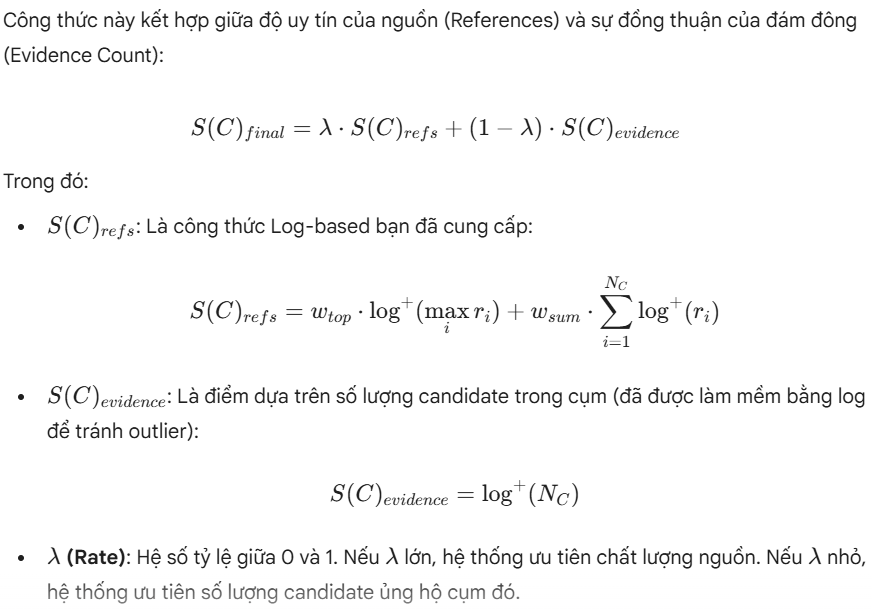

In [189]:
import math

# =========================
# CONFIG HYBRID SCORING 2a
# =========================
W_TOP = 0.6          # Trọng số cho candidate mạnh nhất (như gợi ý ảnh 2)
W_SUM = 0.4          # Trọng số cho tổng các refer (như gợi ý ảnh 2)
LAMBDA_RATE = 0.7    # Tỷ lệ ưu tiên: 0.7 cho Refer, 0.3 cho Evidence Count
MIN_SCORE_THRESHOLD = 1.5

def log_plus(x):
    """Hàm log+(x) = log(1 + x) dùng để làm mềm ảnh hưởng outlier"""
    return math.log(1 + x)

def calculate_hybrid_score(individual_ref_counts, nc):
    """
    Tính toán điểm kết hợp giữa sức mạnh refer và số lượng candidate.
    """
    # 1. Tính S(C) refs dựa trên công thức Log-based
    max_ri = max(individual_ref_counts) if individual_ref_counts else 0
    term_top = log_plus(max_ri)
    term_sum = sum(log_plus(ri) for ri in individual_ref_counts)
    
    s_c_refs = (W_TOP * term_top) + (W_SUM * term_sum)
    
    # 2. Tính S(C) evidence (số lượng candidate trong cụm)
    s_c_evidence = log_plus(nc)
    
    # 3. Kết hợp theo tỷ lệ LAMBDA_RATE
    final_score = (LAMBDA_RATE * s_c_refs) + ((1 - LAMBDA_RATE) * s_c_evidence)
    
    return final_score

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Danh sách số refer của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices) # Số lượng candidate trong cụm
                
                # Tính điểm theo công thức Hybrid mới
                c_score = calculate_hybrid_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất trong cụm tốt nhất làm final answer
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    return fused_results, list(list_id_miss)

## Công thức 2B
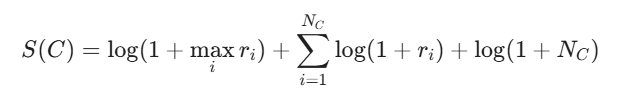

In [20]:
# CÔng thức 2b
MIN_SCORE_THRESHOLD = 3

def log_plus(x):
    """Hàm log+(x) = log(1 + x) dùng để làm mềm ảnh hưởng outlier"""
    return math.log(1 + x)

def calculate_new_score(individual_ref_counts, nc):
    """
    Tính toán điểm dựa trên công thức mới:
    S(C) = log(1 + max r_i) + sum(log(1 + r_i)) + log(1 + Nc)
    """
    # 1. Thành phần log(1 + max r_i) - Ưu tiên ứng viên mạnh nhất
    max_ri = max(individual_ref_counts) if individual_ref_counts else 0
    term_max = log_plus(max_ri)
    
    # 2. Thành phần sum(log(1 + r_i)) - Ưu tiên cụm có tổng lượng tham chiếu lớn
    term_sum_all = sum(log_plus(ri) for ri in individual_ref_counts)
    
    # 3. Thành phần log(1 + Nc) - Ưu tiên cụm có số lượng ứng viên đông
    term_nc = log_plus(nc)
    
    # Tổng hợp theo công thức mới trong ảnh
    final_score = term_max + term_sum_all + term_nc
    
    return final_score

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}
    count_ref = [0]*50
    
    cnt = 0
    cnt_true = 0
    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        list_golden = dict_golden[qidx]['True']
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            # Lưu ý: Đảm bảo AgglomerativeClustering và DISTANCE_THRESHOLD đã được định nghĩa
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Danh sách số refer của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices) # Số lượng candidate trong cụm
                
                # Tính điểm theo công thức mới
                c_score = calculate_new_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score
                })
        # else:
        #     if len(cand_list) == 1:
        #         cnt += 1
        #         if cand_list[0]['text'].lower() in list_golden:
        #             ref_cnt = len(cand_list[0]['sources'])
        #             count_ref[ref_cnt] += 1
        #             cnt_true += 1
                    
        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất trong cụm tốt nhất làm final answer
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }
    print("len = 1: ", cnt)
    print("len = 1, true", cnt_true)
    print(count_ref)
    return fused_results, list(list_id_miss)

In [53]:
import math
import numpy as np
from sklearn.cluster import AgglomerativeClustering

# Công thức 2b
MIN_SCORE_THRESHOLD = 6.5

def log_plus(x):
    return math.log(1 + x)

def calculate_new_score(individual_ref_counts, nc):
    max_ri = max(individual_ref_counts) if individual_ref_counts else 0
    term_max = log_plus(max_ri)
    term_sum_all = sum(log_plus(ri) for ri in individual_ref_counts)
    term_nc = log_plus(nc)
    return term_max + term_sum_all + term_nc

def cluster_and_evaluate(processed_data, model, dict_golden, embedding_cache=None):
    """
    embedding_cache: dict truyền từ ngoài vào để lưu trữ/tái sử dụng embeddings.
                     Nếu là None, hàm sẽ tự khởi tạo cache tạm thời.
    """
    if embedding_cache is None:
        embedding_cache = {}
        
    fused_results = {}
    list_id_miss = set()
    
    for qidx, cand_list in processed_data.items():
        if not cand_list:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        # --- QUẢN LÝ CACHE THEO QIDX ---
        if qidx in embedding_cache:
            embeddings = embedding_cache[qidx]
        else:
            texts = [c["text"] for c in cand_list]
            embeddings = model.encode(texts)
            embedding_cache[qidx] = embeddings
        
        # 1. PHÂN CỤM
        raw_clusters = []
        if len(cand_list) >= 2:         
            # Đảm bảo DISTANCE_THRESHOLD đã được định nghĩa trong phạm vi sử dụng
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices)
                c_score = calculate_new_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "cluster_score": c_score
                })
        else:
            # 1 candidate vẫn tính điểm bình thường
            ref_counts = [len(cand_list[0]["sources"])]
            raw_clusters.append({
                "indices": [0],
                "cluster_score": calculate_new_score(ref_counts, 1)
            })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        # 3. GỘP CANDIDATE CÙNG TEXT TRONG CỤM (UPDATE SOURCE)
        chosen_indices = best_cluster_info["indices"]
        merged_in_cluster = {}

        for idx in chosen_indices:
            cand = cand_list[idx]
            norm_text = cand["text"]
            
            if norm_text not in merged_in_cluster:
                merged_in_cluster[norm_text] = {
                    "text": cand["text"],
                    "sources": set(cand.get("sources", [])),
                    "context": cand.get("context", "")
                }
            else:
                merged_in_cluster[norm_text]["sources"].update(cand.get("sources", []))

        # 4. CHỌN KẾT QUẢ CUỐI CÙNG (Max source count sau merge)
        final_candidate = max(merged_in_cluster.values(), key=lambda x: len(x["sources"]))

        fused_results[qidx] = {
            "final_answer": final_candidate["text"],
            "context": final_candidate["context"],
            "sources": list(final_candidate["sources"]),
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    return fused_results, list(list_id_miss), embedding_cache

In [ ]:
import math
import numpy as np
from sklearn.cluster import AgglomerativeClustering

# Cấu hình ngưỡng (Thresholds)
MIN_SCORE_THRESHOLD = 6.5

def log_plus(x):
    return math.log(1 + x)

def calculate_new_score(individual_ref_counts, nc):
    if not individual_ref_counts:
        return 0
    max_ri = max(individual_ref_counts)
    term_max = log_plus(max_ri)
    term_sum_all = sum(log_plus(ri) for ri in individual_ref_counts)
    term_nc = log_plus(nc)
    return term_max + term_sum_all + term_nc

def cluster_and_evaluate(processed_data, model, dict_golden, embedding_cache=None):
    """
    embedding_cache: dict { "văn bản candidate": embedding_vector }
    """
    if embedding_cache is None:
        embedding_cache = {}
        
    fused_results = {}
    list_id_miss = set()
    
    for qidx, cand_list in processed_data.items():
        if not cand_list:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        # --- QUẢN LÝ CACHE THEO TỪNG CANDIDATE TEXT ---
        texts = [c["text"] for c in cand_list]
        unique_texts = list(set(texts))
        
        # Tìm các text chưa có trong cache để encode 1 lần (batch encoding)
        texts_to_encode = [t for t in unique_texts if t not in embedding_cache]
        if texts_to_encode:
            new_embeddings = model.encode(texts_to_encode)
            for t, emb in zip(texts_to_encode, new_embeddings):
                embedding_cache[t] = emb
        
        # Tạo ma trận embeddings cho list hiện tại từ cache
        current_embeddings = np.array([embedding_cache[t] for t in texts])
        
        # 1. PHÂN CỤM
        raw_clusters = []
        if len(cand_list) >= 2:         
            # Sử dụng AgglomerativeClustering với ma trận đã lấy từ cache
            clustering_model = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", 
                linkage="average"
            )
            labels = clustering_model.fit(current_embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices)
                c_score = calculate_new_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "cluster_score": c_score
                })
        else:
            # Trường hợp chỉ có 1 candidate
            ref_counts = [len(cand_list[0]["sources"])]
            raw_clusters.append({
                "indices": [0],
                "cluster_score": calculate_new_score(ref_counts, 1)
            })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        # 3. GỘP CANDIDATE CÙNG TEXT TRONG CỤM (UPDATE SOURCE)
        chosen_indices = best_cluster_info["indices"]
        merged_in_cluster = {}

        for idx in chosen_indices:
            cand = cand_list[idx]
            norm_text = cand["text"]
            
            if norm_text not in merged_in_cluster:
                merged_in_cluster[norm_text] = {
                    "text": cand["text"],
                    "sources": set(cand.get("sources", [])),
                    "context": cand.get("context", ""),
                    "long_answer": cand.get('long_answer', "")
                }
            else:
                merged_in_cluster[norm_text]["sources"].update(cand.get("sources", []))

        # 4. CHỌN KẾT QUẢ CUỐI CÙNG (Max source count sau khi merge text)
        final_candidate = max(merged_in_cluster.values(), key=lambda x: len(x["sources"]))

        fused_results[qidx] = {
            "final_answer": final_candidate["text"],
            "context": final_candidate["context"],
            "sources": list(final_candidate["sources"]),
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }
    save_embedding_cache(embedding_cache, 'data/cache/embed_candidate_ans_cluster.json')
    return fused_results, list(list_id_miss), embedding_cache

In [ ]:
# # CÔng thức 2bb
# MIN_SCORE_THRESHOLD = 3

# def log_plus(x):
#     """Hàm log+(x) = log(1 + x) dùng để làm mềm ảnh hưởng outlier"""
#     return math.log(1 + x)

# def calculate_new_score(individual_ref_counts, nc):
#     """
#     Tính toán điểm dựa trên công thức mới:
#     S(C) = log(1 + max r_i) + sum(log(1 + r_i)) + log(1 + Nc)
#     """
#     # 1. Thành phần log(1 + max r_i) - Ưu tiên ứng viên mạnh nhất
#     max_ri = max(individual_ref_counts) if individual_ref_counts else 0
#     term_max = log_plus(max_ri)
    
#     # 2. Thành phần sum(log(1 + r_i)) - Ưu tiên cụm có tổng lượng tham chiếu lớn
#     term_sum_all = sum(log_plus(ri) for ri in individual_ref_counts)
    
#     # 3. Thành phần log(1 + Nc) - Ưu tiên cụm có số lượng ứng viên đông
#     term_nc = log_plus(nc)
    
#     # Tổng hợp theo công thức mới trong ảnh
#     final_score = term_max + term_sum_all + term_nc
    
#     return final_score

# def cluster_and_evaluate(processed_data, model, dict_golden):
#     fused_results = {}
#     list_id_miss = set()
#     cache_miss = {}
#     count_ref = [0]*50
#     stats_single_cand = defaultdict(lambda: {"total": 0, "correct": 0})
#     cnt_len_1 = 0
#     cnt_true_len_1 = 0
    
#     cnt = 0
#     cnt_true = 0
#     for qidx, cand_list in processed_data.items():
#         if cand_list is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.add(qidx)
#             continue
        
#         list_golden = dict_golden[qidx]['True']
        
#         texts = [c["text"] for c in cand_list]
#         embeddings = model.encode(texts)
#         raw_clusters = []

#         if len(cand_list) >= 2:        
#             # Lưu ý: Đảm bảo AgglomerativeClustering và DISTANCE_THRESHOLD đã được định nghĩa
#             labels = AgglomerativeClustering(
#                 n_clusters=None,
#                 distance_threshold=DISTANCE_THRESHOLD,
#                 metric="cosine", linkage="average"
#             ).fit(embeddings).labels_

#             for lbl in set(labels):
#                 indices = [i for i, l in enumerate(labels) if l == lbl]
                
#                 # Danh sách số refer của từng candidate trong cụm
#                 individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
#                 nc = len(indices) # Số lượng candidate trong cụm
                
#                 # Tính điểm theo công thức mới
#                 c_score = calculate_new_score(individual_ref_counts, nc)
                
#                 raw_clusters.append({
#                     "indices": indices,
#                     "evidence_count": nc,
#                     "cluster_score": c_score
#                 })
#         else:
#             if len(cand_list) == 1:
#                 cnt_len_1 += 1
#                 cand = cand_list[0]
#                 ref_cnt = len(cand['sources'])
#                 is_correct = cand['text'].lower() in list_golden
                
#                 # Cập nhật thống kê
#                 stats_single_cand[ref_cnt]["total"] += 1
#                 if is_correct:
#                     stats_single_cand[ref_cnt]["correct"] += 1
#                     cnt_true_len_1 += 1
                
#                 # Kết quả cho fused_results
#                 fused_results[qidx] = {
#                     "final_answer": cand["text"],
#                     "abstain": False,
#                     "ref_count": ref_cnt
#                 }
                    
#         # 2. CHỌN CLUSTER TỐT NHẤT
#         best_cluster_info = None
#         if raw_clusters:
#             candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
#             if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
#                 best_cluster_info = candidate_best

#         # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
#         if best_cluster_info is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.add(qidx)
#             continue
        
#         chosen_indices = best_cluster_info["indices"]
#         # Chọn candidate có nhiều refer nhất trong cụm tốt nhất làm final answer
#         best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

#         fused_results[qidx] = {
#             "final_answer": cand_list[best_idx]["text"],
#             "context": cand_list[best_idx]["context"],
#             "abstain": False,
#             "debug_score": round(best_cluster_info["cluster_score"], 4)
#         }
#     # print("len = 1: ", cnt)
#     # print("len = 1, true", cnt_true)
#     # print(count_ref)
    
#     print(f"Tổng số câu có 1 candidate: {cnt_len_1}")
#     print(f"Tổng số câu đúng: {cnt_true_len_1}")
#     print(f"{'Số Refer'} | {'Tổng số câu'} | {'Độ chính xác trung bình'}")
#     for r in sorted(stats_single_cand.keys()):
#         total = stats_single_cand[r]["total"]
#         correct = stats_single_cand[r]["correct"]
#         accuracy = (correct / total) * 100 if total > 0 else 0
#         print(f"{r} | {total} | {accuracy}%")
    
#     return fused_results, list(list_id_miss)

In [23]:
# MIN_SCORE_THRESHOLD = 7

# def cluster_and_evaluate_refined(processed_data, model, distance_threshold, min_score_threshold):
#     fused_results = {}
#     list_id_miss = []

#     for qidx, cand_list in processed_data.items():
#         if not cand_list:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.append(qidx)
#             continue
        
#         raw_clusters = []
#         # FIX LỖI 1: Xử lý cả khi len < 2
#         if len(cand_list) >= 2:
#             texts = [c["text"] for c in cand_list]
#             embeddings = model.encode(texts)
#             labels = AgglomerativeClustering(
#                 n_clusters=None,
#                 distance_threshold=distance_threshold,
#                 metric="cosine", linkage="average"
#             ).fit(embeddings).labels_

#             for lbl in set(labels):
#                 indices = [i for i, l in enumerate(labels) if l == lbl]
#                 individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
#                 c_score = calculate_new_score(individual_ref_counts, len(indices))
#                 raw_clusters.append({"indices": indices, "cluster_score": c_score})
#         else:
#             # Trường hợp chỉ có 1 candidate duy nhất
#             ref_counts = [len(cand_list[0]["sources"])]
#             c_score = calculate_new_score(ref_counts, 1)
#             raw_clusters.append({"indices": [0], "cluster_score": c_score})

#         # CHỌN CLUSTER
#         best_cluster_info = None
#         if raw_clusters:
#             candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
#             if candidate_best["cluster_score"] >= min_score_threshold:
#                 best_cluster_info = candidate_best

#         if best_cluster_info is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.append(qidx)
#         else:
#             chosen_indices = best_cluster_info["indices"]
#             # Chọn người có nhiều ref nhất trong cụm thắng cuộc
#             best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))
            
#             fused_results[qidx] = {
#                 "final_answer": cand_list[best_idx]["text"],
#                 "abstain": False,
#                 "debug_score": round(best_cluster_info["cluster_score"], 4)
#             }

#     return fused_results, list_id_miss

# Công thức 4:Power aggregation
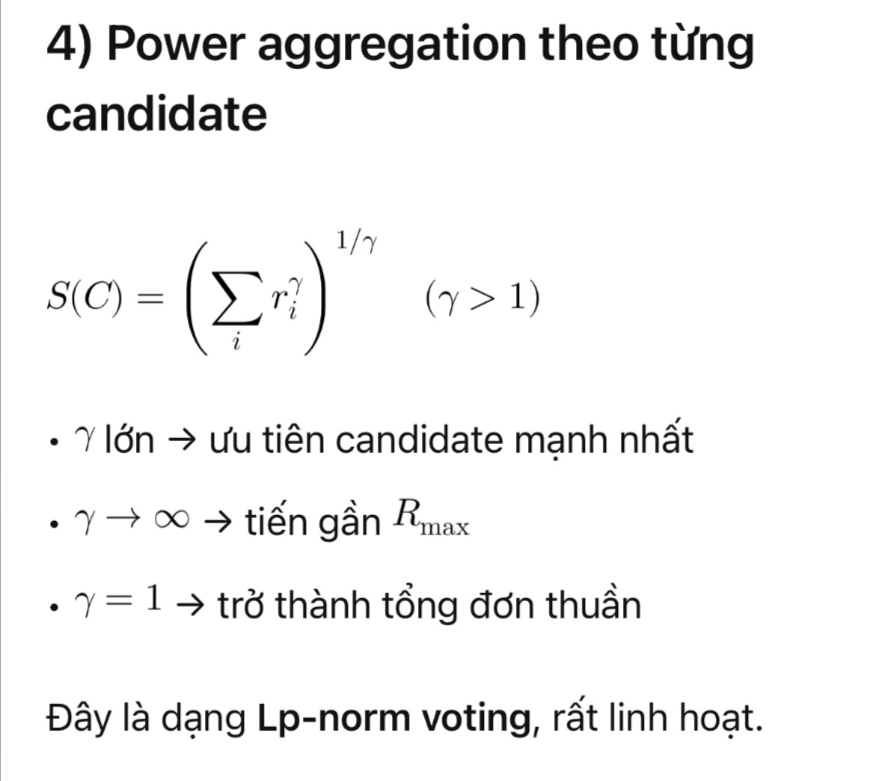
<!-- 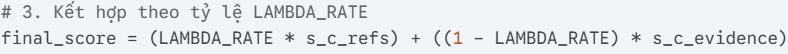 -->

In [198]:
import math

# =========================
# CONFIG POWER AGGREGATION SCORING (Công thức 4)
# =========================
GAMMA = 2.0         # Hệ số Lp-norm. Gamma càng lớn càng ưu tiên candidate mạnh nhất
LAMBDA_RATE = 1 #1 # 0.5    # Tỷ lệ cân bằng giữa sức mạnh refer (Công thức 4) và số lượng candidate theo công thức 4 thì chỉ dùng S(c) => lamda = 1

MIN_SCORE_THRESHOLD = 2.0

def calculate_power_aggregation_score(individual_ref_counts, nc):
    """
    Tính toán điểm dựa trên công thức 4: Power aggregation (Lp-norm voting)
    """
    if not individual_ref_counts:
        return 0.0

    # 1. Tính S(C) refs dựa trên công thức Power aggregation
    # S(C) = (sum(ri^gamma))^(1/gamma)
    sum_power = sum(math.pow(ri, GAMMA) for ri in individual_ref_counts)
    s_c_refs = math.pow(sum_power, 1/GAMMA)
    
    # 2. Tính S(C) evidence (số lượng candidate trong cụm)
    # Dùng log+ để làm mềm ảnh hưởng outlier của số lượng candidate
    s_c_evidence = math.log1p(nc) 
    
    # 3. Kết hợp theo tỷ lệ LAMBDA_RATE
    final_score = (LAMBDA_RATE * s_c_refs) + ((1 - LAMBDA_RATE) * s_c_evidence)
    
    return final_score

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Danh sách số refer (ri) của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices) # Số lượng candidate trong cụm (Nc)
                
                # Tính điểm theo công thức Power Aggregation mới
                c_score = calculate_power_aggregation_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất (Rmax) trong cụm tốt nhất
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    return fused_results, list(list_id_miss)

# Công thức 5: SOFTMAX AGGREGATION
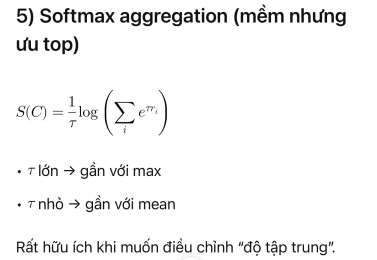

In [28]:
import math

# =========================
# CONFIG SOFTMAX AGGREGATION (Công thức 5)
# =========================
TAU = 1.0              # Tham số điều chỉnh độ tập trung
                     # TAU lớn -> tiến gần giá trị Max (ưu tiên top candidate)
                     # TAU nhỏ -> tiến gần giá trị Mean (cân bằng cả cụm)
                     
LAMBDA_RATE = 1    # Tỷ lệ cân bằng giữa điểm Refer (Công thức 5) và Evidence Count
MIN_SCORE_THRESHOLD = 2.5

def calculate_softmax_aggregation_score(individual_ref_counts, nc):
    """
    Tính toán điểm dựa trên công thức 5: Softmax aggregation (Log-Sum-Exp)
    S(C) = (1/tau) * log( sum( e^(tau * ri) ) )
    """
    if not individual_ref_counts:
        return 0.0

    # 1. Tính S(C) refs dựa trên công thức Softmax aggregation
    # Để tránh lỗi tràn số (overflow) khi tính hàm mũ, ta dùng kỹ thuật Log-Sum-Exp ổn định
    max_r = max(individual_ref_counts)
    sum_exp = sum(math.exp(TAU * (ri - max_r)) for ri in individual_ref_counts)
    
    # Biến đổi toán học: (1/tau) * log(sum(e^(tau*ri))) = max_r + (1/tau) * log(sum(e^(tau*(ri-max_r))))
    s_c_refs = max_r + (1/TAU) * math.log(sum_exp)
    
    # 2. Tính S(C) evidence (số lượng candidate trong cụm)
    # Sử dụng log+ để làm mềm ảnh hưởng của số lượng candidate
    s_c_evidence = math.log1p(nc) 
    
    # 3. Kết hợp theo tỷ lệ LAMBDA_RATE
    final_score = (LAMBDA_RATE * s_c_refs) + ((1 - LAMBDA_RATE) * s_c_evidence)
    
    return final_score

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Danh sách số refer (ri) của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices) # Số lượng candidate trong cụm (Nc)
                
                # Tính điểm theo công thức Softmax Aggregation mới
                c_score = calculate_softmax_aggregation_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất trong cụm tốt nhất
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    return fused_results, list(list_id_miss)

#  Công thức 6: Gini / Concentration Adjusted
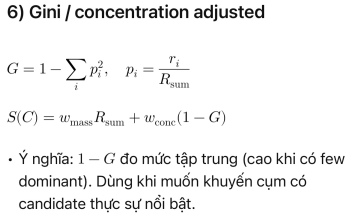

In [ ]:
# import math
# import os
# import json

# # =========================
# # CONFIG GINI / CONCENTRATION ADJUSTED (Công thức 6)
# # =========================
# W_MASS = 0.5          # Trọng số cho tổng khối lượng bằng chứng (R_sum)
# W_CONC = 0.5        # Trọng số cho mức độ tập trung (1 - G)
# MIN_SCORE_THRESHOLD = 2.0

# def calculate_gini_adjusted_score(individual_ref_counts):
#     """
#     Tính toán điểm dựa trên công thức 6: Gini / Concentration Adjusted
#     S(C) = w_mass * R_sum + w_conc * (1 - G)
#     """
#     if not individual_ref_counts or sum(individual_ref_counts) == 0:
#         return 0.0

#     # 1. Tính R_sum (Tổng số refer trong cụm)
#     r_sum = sum(individual_ref_counts)
    
#     # 2. Tính p_i và chỉ số tập trung (1 - G)
#     # (1 - G) = sum( (r_i / r_sum)^2 )
#     concentration = sum([(ri / r_sum)**2 for ri in individual_ref_counts])
    
#     # 3. Tính điểm S(C) refs theo công thức 6
#     s_c_refs = (W_MASS * r_sum) + (W_CONC * concentration)
   
    
#     return s_c_refs

# def cluster_and_evaluate(processed_data, model, dict_golden):
#     fused_results = {}
#     list_id_miss = set()
#     cache_miss = {}

#     for qidx, cand_list in processed_data.items():
#         if cand_list is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.add(qidx)
#             # Lưu cache miss cho trường hợp không có candidate
#             cache_miss[qidx] = {
#                 "reason": "no_candidate",
#                 "golden": dict_golden.get(qidx, {}).get("True", []),
#                 "num_clusters": 0,
#                 "clusters": [],
#                 "candidates": None
#             }
#             continue
        
#         texts = [c["text"] for c in cand_list]
#         embeddings = model.encode(texts)
#         raw_clusters = []

#         if len(cand_list) >= 2:        
#             from sklearn.cluster import AgglomerativeClustering
#             labels = AgglomerativeClustering(
#                 n_clusters=None,
#                 distance_threshold=0.12, # Giả định threshold cố định
#                 metric="cosine", linkage="average"
#             ).fit(embeddings).labels_

#             for lbl in set(labels):
#                 indices = [i for i, l in enumerate(labels) if l == lbl]
                
#                 # Danh sách số refer (ri) của từng candidate trong cụm
#                 individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]

#                 nc = len(indices)
#                 # Tính điểm theo công thức Gini Adjusted mới
#                 c_score = calculate_gini_adjusted_score(individual_ref_counts)
                
#                 raw_clusters.append({
#                     "indices": indices,
#                     "evidence_count": nc,
#                     "cluster_score": c_score,
#                     "unique_source": sum(individual_ref_counts)
#                 })

#         # 2. CHỌN CLUSTER TỐT NHẤT DỰA TRÊN SCORE TỔNG HỢP
#         best_cluster_info = None
#         if raw_clusters:
#             candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
#             if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
#                 best_cluster_info = candidate_best

#         # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
#         if best_cluster_info is None:
#             fused_results[qidx] = {"abstain": True}
#             list_id_miss.add(qidx)
#             # Lưu cache miss chi tiết để debug
#             cache_miss[qidx] = {
#                 "reason": "no_cluster_selected",
#                 "golden": dict_golden.get(qidx, {}).get("True", []),
#                 "num_clusters": len(raw_clusters),
#                 "clusters": raw_clusters,
#                 "candidates": cand_list
#             }
#             continue
        
#         chosen_indices = best_cluster_info["indices"]
#         # Chọn candidate có nhiều refer nhất (R_max) trong cụm tốt nhất
#         best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

#         fused_results[qidx] = {
#             "final_answer": cand_list[best_idx]["text"],
#             "context": cand_list[best_idx]["context"],
#             "abstain": False,
#             "debug_score": round(best_cluster_info["cluster_score"], 4)
#         }

#     # Lưu log các câu không chọn được kết quả (tùy chọn)
#     os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
#     file_miss = fr'src\cluster\cache\select_final_ans\{len(list_id_miss)}q_khong_lay.json'
#     with open(file_miss, 'w', encoding='utf-8') as f:
#         json.dump(cache_miss, f, ensure_ascii=False, indent=4)

#     return fused_results, list(list_id_miss)

In [5]:
import math
import os
import json
from sklearn.cluster import AgglomerativeClustering

# =========================
# CONFIG GINI / CONCENTRATION ADJUSTED (Công thức 66)
# =========================
W_MASS = 0.7          # Trọng số cho tổng khối lượng bằng chứng (R_sum)
W_CONC = 0.3          # Trọng số cho mức độ tập trung (1 - G)
MIN_SCORE_THRESHOLD = 2.0
DISTANCE_THRESHOLD = 0.12

def calculate_gini_adjusted_score(individual_ref_counts):
    """
    Tính toán điểm dựa trên công thức 6: Gini / Concentration Adjusted
    S(C) = w_mass * R_sum + w_conc * (1 - G)
    """
    if not individual_ref_counts or sum(individual_ref_counts) == 0:
        return 0.0

    # 1. Tính R_sum (Tổng số refer trong cụm)
    r_sum = sum(individual_ref_counts)
    
    # 2. Tính p_i và chỉ số tập trung (1 - G)
    # (1 - G) = sum( (r_i / r_sum)^2 )
    concentration = sum([(ri / r_sum)**2 for ri in individual_ref_counts])
    
    # 3. Tính điểm S(C) theo công thức 6
    s_c_refs = (W_MASS * r_sum) + (W_CONC * concentration)
    
    return s_c_refs

def cluster_and_evaluate(processed_data, model, dict_golden, embedding_cache=None):
    if embedding_cache is None:
        embedding_cache = {}

    fused_results = {}
    list_id_miss = set()
    cache_miss = {}
    
    cnt = 0
    cnt_true = 0
    for qidx, cand_list in processed_data.items():
        if not cand_list:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0,
                "clusters": [],
                "candidates": None
            }
            continue
        
        # --- BƯỚC CACHE EMBEDDING ---
        if qidx in embedding_cache:
            embeddings = embedding_cache[qidx]
        else:
            texts = [c["text"] for c in cand_list]
            embeddings = model.encode(texts)
            embedding_cache[qidx] = embeddings
            
        raw_clusters = []

        # 1. PHÂN CỤM (Xử lý cả 1 candidate và n candidates)
        if len(cand_list) >= 2:         
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                
                c_score = calculate_gini_adjusted_score(individual_ref_counts)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": len(indices),
                    "cluster_score": c_score,
                    "unique_source": sum(individual_ref_counts)
                })
        else:
            # Trường hợp 1 candidate: 1 cluster bình thường
            ref_counts = [len(cand_list[0]["sources"])]
            raw_clusters.append({
                "indices": [0],
                "evidence_count": 1,
                "cluster_score": calculate_gini_adjusted_score(ref_counts),
                "unique_source": ref_counts[0]
            })
            cnt += 1
            if cand_list[0]['text'] in dict_golden[qidx]['True']:
                cnt_true += 1

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_cluster_selected",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": len(raw_clusters),
                "clusters": raw_clusters,
                "candidates": cand_list
            }
            continue
        
        # 3. MERGE CANDIDATES GIỐNG NHAU TRONG CLUSTER ĐÃ CHỌN
        chosen_indices = best_cluster_info["indices"]
        merged_in_cluster = {}

        for idx in chosen_indices:
            cand = cand_list[idx]
            norm_text = cand["text"].strip()
            
            if norm_text not in merged_in_cluster:
                merged_in_cluster[norm_text] = {
                    "text": cand["text"],
                    "sources": set(cand.get("sources", [])),
                    "context": cand.get("context", "")
                }
            else:
                merged_in_cluster[norm_text]["sources"].update(cand.get("sources", []))

        # 4. CHỌN FINAL ANSWER (Candidate có sources cao nhất sau merge)
        final_candidate = max(merged_in_cluster.values(), key=lambda x: len(x["sources"]))

        fused_results[qidx] = {
            "final_answer": final_candidate["text"],
            "context": final_candidate["context"],
            "sources": list(final_candidate["sources"]),
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    # Lưu log miss (Giữ nguyên logic của bạn)
    os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
    file_miss = fr'src\cluster\cache\select_final_ans\{len(list_id_miss)}q_khong_lay.json'
    with open(file_miss, 'w', encoding='utf-8') as f:
        json.dump(cache_miss, f, ensure_ascii=False, indent=4)

    print(cnt_true, cnt, cnt_true/cnt)
    return fused_results, list(list_id_miss), embedding_cache

# Công thức 7: Bayesian posterior score
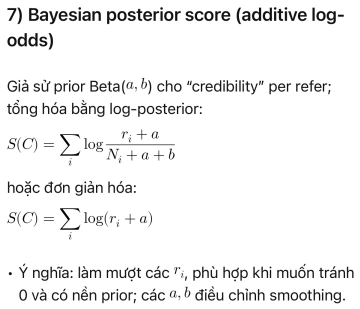

In [210]:
import math

# =========================
# CONFIG BAYESIAN POSTERIOR SCORE (Công thức 7)
# =========================
# Tham số a (prior) giúp tránh giá trị 0 và điều chỉnh mức độ làm mượt.
# Giá trị a > 0. Thường chọn a = 1.0 hoặc nhỏ hơn tùy độ nhạy mong muốn.
PRIOR_A = 1.0

# Tỷ lệ cân bằng giữa điểm Bayesian (Công thức 7) và Evidence Count
LAMBDA_RATE = 1
MIN_SCORE_THRESHOLD = 1.5

def calculate_bayesian_posterior_score(individual_ref_counts, a=PRIOR_A):
    """
    Tính toán điểm dựa trên công thức 7: Bayesian posterior score (dạng đơn giản hóa)
    S(C) = sum( log(r_i + a) )
    """
    if not individual_ref_counts:
        return 0.0

    # 1. Tính tổng log(r_i + a) theo từng candidate trong cụm
    # r_i là số refer của candidate thứ i
    s_c_refs = sum(math.log(ri + a) for ri in individual_ref_counts)
    
    return s_c_refs

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            from sklearn.cluster import AgglomerativeClustering
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=0.12, 
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Danh sách số refer (ri) của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices) 
                
                # 1. Tính điểm Refer theo Công thức 7
                s_c_refs = calculate_bayesian_posterior_score(individual_ref_counts)
                
                # 2. Tính điểm Evidence (Nc) để tăng tính đồng thuận
                s_c_evidence = math.log1p(nc)
                
                # 3. Kết hợp theo tỷ lệ
                c_score = (LAMBDA_RATE * s_c_refs) + ((1 - LAMBDA_RATE) * s_c_evidence)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT DỰA TRÊN SCORE TỔNG HỢP
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất trong cụm tốt nhất
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    return fused_results, list(list_id_miss)

# Công thức 8; Entropy
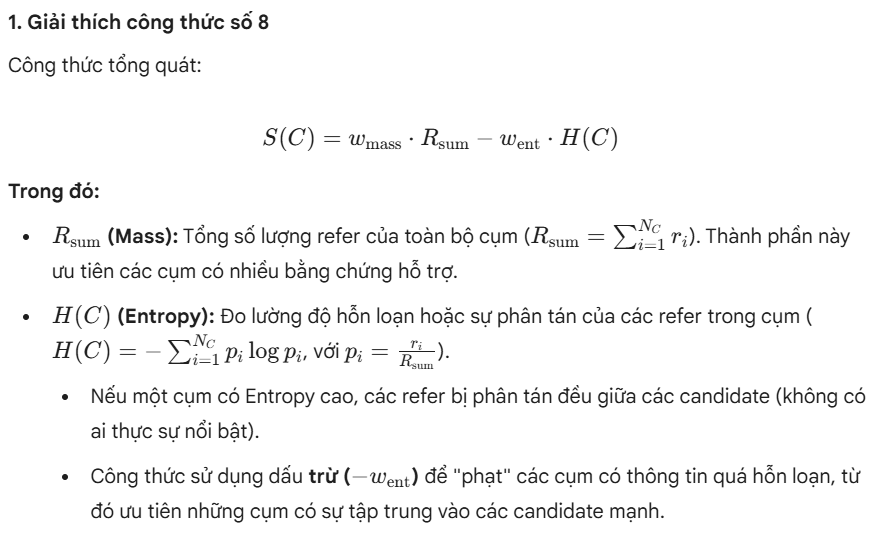

In [213]:
import math
import os
import json

# =========================
# CONFIG ENTROPY-PENALIZED MASS (Công thức 8)
# =========================
W_MASS = 1.2          # Trọng số cho tổng khối lượng bằng chứng (R_sum)
W_ENT = 1.2          # Trọng số phạt Entropy (ưu tiên sự tập trung, phạt sự phân tán)
LAMBDA_RATE = 1     # Tỷ lệ cân bằng giữa điểm Refer (Công thức 8) và Evidence Count
MIN_SCORE_THRESHOLD = 2.25

def calculate_entropy_penalized_score(individual_ref_counts):
    """
    Tính toán điểm dựa trên công thức 8: Entropy-penalized Mass
    S(C) = w_mass * R_sum - w_ent * H(C)
    """
    if not individual_ref_counts or sum(individual_ref_counts) == 0:
        return 0.0

    # 1. Tính R_sum (Tổng số refer trong toàn cụm)
    r_sum = sum(individual_ref_counts)
    
    # 2. Tính Entropy H(C)
    # H(C) = -sum( p_i * log(p_i) ) với p_i = r_i / r_sum
    entropy = 0
    for ri in individual_ref_counts:
        if ri > 0:
            pi = ri / r_sum
            entropy -= pi * math.log(pi)
            
    # 3. Tính điểm S(C) refs
    # Phạt các cụm có entropy cao (thông tin phân tán)
    s_c_refs = (W_MASS * r_sum) - (W_ENT * entropy)
    
    return s_c_refs

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            # Cache miss cho trường hợp không có candidate
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0,
                "clusters": [],
                "candidates": None
            }
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            from sklearn.cluster import AgglomerativeClustering
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=0.12, 
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Số refer (ri) của từng candidate
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices) 
                
                # 1. Tính điểm Refer theo Công thức 8
                s_c_refs = calculate_entropy_penalized_score(individual_ref_counts)
                
                # 2. Tính điểm Evidence (Nc) làm mềm bằng log1p
                s_c_evidence = math.log1p(nc)
                
                # 3. Kết hợp Hybrid
                c_score = (LAMBDA_RATE * s_c_refs) + ((1 - LAMBDA_RATE) * s_c_evidence)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score,
                    "entropy": 0 # Có thể lưu thêm entropy để debug
                })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_cluster_selected",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": len(raw_clusters),
                "clusters": raw_clusters,
                "candidates": cand_list
            }
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất trong cụm
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    # Lưu cache miss để phân tích
    os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
    file_miss = fr'src\cluster\cache\select_final_ans\{len(list_id_miss)}q_khong_lay.json'
    with open(file_miss, 'w', encoding='utf-8') as f:
        json.dump(cache_miss, f, ensure_ascii=False, indent=4)

    return fused_results, list(list_id_miss)

In [1]:
import math
import os
import json
import numpy as np
from sklearn.cluster import AgglomerativeClustering

# =========================
# CONFIG GINI / CONCENTRATION ADJUSTED (Công thức 6)
# =========================
W_MASS = 0.7          # Trọng số cho tổng khối lượng bằng chứng (R_sum)
W_CONC = 0.3          # Trọng số cho mức độ tập trung (1 - G)
MIN_SCORE_THRESHOLD = 2.0
DISTANCE_THRESHOLD = 0.12

def calculate_gini_adjusted_score(individual_ref_counts):
    """
    S(C) = w_mass * R_sum + w_conc * (1 - G)
    """
    if not individual_ref_counts or sum(individual_ref_counts) == 0:
        return 0.0

    r_sum = sum(individual_ref_counts)
    concentration = sum([(ri / r_sum)**2 for ri in individual_ref_counts])
    s_c_refs = (W_MASS * r_sum) + (W_CONC * concentration)
    
    return s_c_refs

def cluster_and_evaluate(processed_data, model, dict_golden, embedding_cache=None):
    if embedding_cache is None:
        embedding_cache = {}

    fused_results = {}
    list_id_miss = set()
    cache_miss = {}
    
    cnt = 0
    cnt_true = 0
    
    for qidx, cand_list in processed_data.items():
        if not cand_list:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            # ... (giữ nguyên logic log miss)
            continue
        
        # --- CACHE EMBEDDING ---
        current_texts = [c["text"] for c in cand_list]
        embeddings = []
        texts_to_encode = []
        indices_to_encode = []

        for i, txt in enumerate(current_texts):
            if txt in embedding_cache:
                embeddings.append(embedding_cache[txt])
            else:
                embeddings.append(None)
                texts_to_encode.append(txt)
                indices_to_encode.append(i)

        if texts_to_encode:
            new_embs = model.encode(texts_to_encode)
            for i, emb in enumerate(new_embs):
                embedding_cache[texts_to_encode[i]] = emb
                embeddings[indices_to_encode[i]] = emb
        
        embeddings_np = np.array(embeddings)
            
        raw_clusters = []

        # 1. PHÂN CỤM
        if len(cand_list) >= 2:         
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=DISTANCE_THRESHOLD,
                metric="cosine", linkage="average"
            ).fit(embeddings_np).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                c_score = calculate_gini_adjusted_score(individual_ref_counts)
                raw_clusters.append({
                    "indices": indices,
                    "cluster_score": c_score,
                })
        else:
            raw_clusters.append({
                "indices": [0],
                "cluster_score": calculate_gini_adjusted_score([len(cand_list[0]["sources"])]),
            })
            cnt += 1
            if cand_list[0]['text'] in dict_golden.get(qidx, {}).get('True', []):
                cnt_true += 1

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            # ... (log miss)
            continue
        
        # 3. MERGE CANDIDATES & CỘNG DỒN LONG ANSWER (CONTEXT)
        chosen_indices = best_cluster_info["indices"]
        merged_in_cluster = {}

        for idx in chosen_indices:
            cand = cand_list[idx]
            norm_text = cand["text"].strip()
            new_context = cand.get("context", "").strip()
            
            if norm_text not in merged_in_cluster:
                merged_in_cluster[norm_text] = {
                    "text": cand["text"],
                    "sources": set(cand.get("sources", [])),
                    "contexts": [new_context] if new_context else []
                }
            else:
                merged_in_cluster[norm_text]["sources"].update(cand.get("sources", []))
                if new_context and new_context not in merged_in_cluster[norm_text]["contexts"]:
                    merged_in_cluster[norm_text]["contexts"].append(new_context)

        # 4. CHỌN FINAL ANSWER VÀ NỐI CHUỖI CONTEXT
        final_candidate = max(merged_in_cluster.values(), key=lambda x: len(x["sources"]))
        
        # Cộng dồn context: Nối các đoạn context bằng dấu xuống dòng hoặc khoảng trắng
        combined_context = "\n".join(final_candidate["contexts"])

        fused_results[qidx] = {
            "final_answer": final_candidate["text"],
            "context": combined_context, # Đây là long_answer đã được cộng dồn
            "sources": list(final_candidate["sources"]),
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    save(embedding_cache, "data/cache/embedding_cache_candidate_cluster.json")
    return fused_results, list(list_id_miss), embedding_cache

# Công thức 9: LOG-AGGREGATION
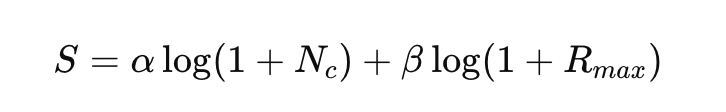

In [216]:
ALPHA = 0.5  # Trọng số cho số lượng candidate trong cụm (Nc)
BETA = 0.5   # Trọng số cho candidate mạnh nhất (Rmax)
MIN_SCORE_THRESHOLD = 0.7

def calculate_log_aggregation_score(nc, max_ri):
    """
    Tính toán điểm dựa trên công thức 9:
    S = alpha * log(1 + Nc) + beta * log(1 + Rmax)
    """
    # log1p(x) tương đương với log(1 + x) nhưng chính xác hơn với x nhỏ
    term_nc = ALPHA * math.log1p(nc)
    term_rmax = BETA * math.log1p(max_ri)
    
    return term_nc + term_rmax

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0,
                "clusters": [],
                "candidates": None
            }
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            from sklearn.cluster import AgglomerativeClustering
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=0.12, 
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Lấy số refer (ri) của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices)
                rmax = max(individual_ref_counts) if individual_ref_counts else 0
                
                # 1. Tính điểm theo Công thức 9
                c_score = calculate_log_aggregation_score(nc, rmax)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "rmax": rmax,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_cluster_selected",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": len(raw_clusters),
                "clusters": raw_clusters,
                "candidates": cand_list
            }
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất trong cụm
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    # Lưu cache miss để phân tích
    os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
    file_miss = fr'src\cluster\cache\select_final_ans\{len(list_id_miss)}q_khong_lay.json'
    with open(file_miss, 'w', encoding='utf-8') as f:
        json.dump(cache_miss, f, ensure_ascii=False, indent=4)

    return fused_results, list(list_id_miss)

# Công thức 10
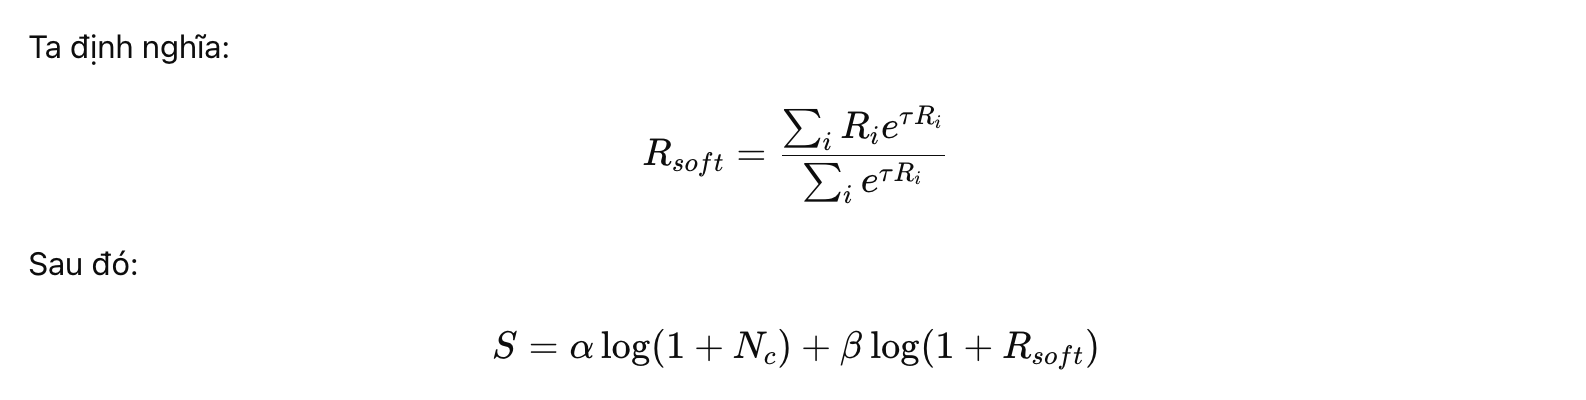

In [219]:
# CONFIG SOFTMAX-WEIGHTED AGGREGATION (Công thức 10)

ALPHA = 0.5         # Trọng số cho quy mô cụm (Nc)
BETA = 0.5           # Trọng số cho chất lượng tham chiếu (Rsoft)
TAU = 0.8         # Tham số điều chỉnh độ "nhạy" của Rsoft
MIN_SCORE_THRESHOLD = 1.0

def calculate_softmax_weighted_score(individual_ref_counts, nc):
    """
    Tính toán điểm dựa trên Công thức 10:
    R_soft = sum(ri * e^(tau * ri)) / sum(e^(tau * ri))
    S = alpha * log(1 + Nc) + beta * log(1 + R_soft)
    """
    if not individual_ref_counts:
        return 0.0

    # 1. Tính R_soft
    # Để tránh lỗi tràn số (overflow) với hàm exp, dùng kỹ thuật trừ max_r
    max_r = max(individual_ref_counts)
    numerator = sum(ri * math.exp(TAU * (ri - max_r)) for ri in individual_ref_counts)
    denominator = sum(math.exp(TAU * (ri - max_r)) for ri in individual_ref_counts)
    
    r_soft = numerator / denominator if denominator != 0 else 0
    
    # 2. Tính điểm cuối cùng S
    term_nc = ALPHA * math.log1p(nc)
    term_rsoft = BETA * math.log1p(r_soft)
    
    return term_nc + term_rsoft

def cluster_and_evaluate(processed_data, model, dict_golden):
    fused_results = {}
    list_id_miss = set()
    cache_miss = {}

    for qidx, cand_list in processed_data.items():
        if cand_list is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_candidate",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": 0,
                "clusters": [],
                "candidates": None
            }
            continue
        
        texts = [c["text"] for c in cand_list]
        embeddings = model.encode(texts)
        raw_clusters = []

        if len(cand_list) >= 2:        
            from sklearn.cluster import AgglomerativeClustering
            labels = AgglomerativeClustering(
                n_clusters=None,
                distance_threshold=0.12, 
                metric="cosine", linkage="average"
            ).fit(embeddings).labels_

            for lbl in set(labels):
                indices = [i for i, l in enumerate(labels) if l == lbl]
                
                # Lấy số refer (ri) của từng candidate trong cụm
                individual_ref_counts = [len(cand_list[i]["sources"]) for i in indices]
                nc = len(indices)
                
                # Tính điểm theo Công thức 10
                c_score = calculate_softmax_weighted_score(individual_ref_counts, nc)
                
                raw_clusters.append({
                    "indices": indices,
                    "evidence_count": nc,
                    "cluster_score": c_score
                })

        # 2. CHỌN CLUSTER TỐT NHẤT
        best_cluster_info = None
        if raw_clusters:
            candidate_best = max(raw_clusters, key=lambda x: x["cluster_score"])
            if candidate_best["cluster_score"] >= MIN_SCORE_THRESHOLD:
                best_cluster_info = candidate_best

        # 3. XỬ LÝ KẾT QUẢ & CHỌN FINAL ANSWER
        if best_cluster_info is None:
            fused_results[qidx] = {"abstain": True}
            list_id_miss.add(qidx)
            cache_miss[qidx] = {
                "reason": "no_cluster_selected",
                "golden": dict_golden.get(qidx, {}).get("True", []),
                "num_clusters": len(raw_clusters),
                "clusters": raw_clusters,
                "candidates": cand_list
            }
            continue
        
        chosen_indices = best_cluster_info["indices"]
        # Chọn candidate có nhiều refer nhất (Rmax) trong cụm tốt nhất làm final answer
        best_idx = max(chosen_indices, key=lambda idx: len(cand_list[idx]["sources"]))

        fused_results[qidx] = {
            "final_answer": cand_list[best_idx]["text"],
            "context": cand_list[best_idx]["context"],
            "abstain": False,
            "debug_score": round(best_cluster_info["cluster_score"], 4)
        }

    # Lưu cache miss để phân tích
    os.makedirs(r'src\cluster\cache\select_final_ans', exist_ok=True)
    file_miss = fr'src\cluster\cache\select_final_ans\{len(list_id_miss)}q_khong_lay.json'
    with open(file_miss, 'w', encoding='utf-8') as f:
        json.dump(cache_miss, f, ensure_ascii=False, indent=4)

    return fused_results, list(list_id_miss)

In [6]:
def compute_selected_summary(fused_results, dict_golden):
    total_with_evidence = len(fused_results)
    selected, correct_selected, total_wrong = 0, 0, 0
    wrong_has_golden_in_ctx, wrong_no_golden_in_ctx = 0, 0
    list_id_wrong = []

    for qidx, info in fused_results.items():
        if info.get("abstain", True):
            continue

        selected += 1
        pred = str(info.get("final_answer", "")).lower().strip()
        context = str(info.get("context", "")).lower()
        golden_list = [str(g).lower().strip() for g in dict_golden.get(qidx, {}).get("True", [])]

        if pred in golden_list:
            correct_selected += 1
        else:
            list_id_wrong.append(qidx)
            total_wrong += 1
            if any(g in context for g in golden_list):
                wrong_has_golden_in_ctx += 1
            else:
                wrong_no_golden_in_ctx += 1

    acc = correct_selected / selected if selected else 0.0
    coverage = selected / total_with_evidence if total_with_evidence else 0.0

    return {
        "total": total_with_evidence, "selected": selected, "correct": correct_selected,
        "acc": acc, "coverage": coverage, "wrong": total_wrong,
        "wrong_in_ctx": wrong_has_golden_in_ctx, "wrong_no_ctx": wrong_no_golden_in_ctx
    }, list_id_wrong

In [7]:
def load_pubmed_model():
    print("Loading embedding model (PubMedBERT)...")    
    return SentenceTransformer("pritamdeka/S-BioBert-snli-multinli-stsb",device="cpu")

In [23]:
BASE_FOLDER = "src/cluster/final"

# PATH_CLUSTER = fr"{BASE_FOLDER}/WH_answer_kmean_merge_google_wiki_7.json"
PATH_GOLDEN = "data/all_answer_golden_56.json"
PATH_MAPPING = 'data/mapping_answer_gol.json'

# PATH_CLUSTER = r"src\cluster\final\WH_answer_kmean_merge_google_wiki_7_new.json"
# PATH_CLUSTER = r"src\cluster\final\WH_answer_kmean_merge_google_wiki_7_old.json"

# PATH_CLUSTER =r'src\cluster\final_v0\WH_answer_kmean_merge_google_wiki_7.json' #double gg
# r'src\cluster\final\WH_answer_CT6_#5.json'
PATH_CLUSTER =   r'src\cluster\final\WH_answer_kmean_merge_google_wiki_7_only_GG.json' #only gg

In [9]:
model = load_pubmed_model()
mapping_data = load_json(PATH_MAPPING)
dict_golden = load_json(PATH_GOLDEN)

Loading embedding model (PubMedBERT)...


In [16]:
print("Step 1: Collecting candidates...")
processed_candidates_mapping = collect_candidates(PATH_CLUSTER, mapping_data)

Step 1: Collecting candidates...


In [24]:
processed_candidates_no_mapping = collect_candidates(PATH_CLUSTER, mapping_data)

In [21]:
#vtmthu MAPPING
results, list_id_miss = cluster_and_evaluate(processed_candidates_mapping, model, dict_golden)
print("MIN_SCORE_THRESHOLD: ", MIN_SCORE_THRESHOLD)
print(len(list_id_miss))
save_json(list_id_miss, f"list_id_miss_ct.json")
stats, list_id_wrong = compute_selected_summary(results, dict_golden)
print(f"Selected Answers   : {stats['selected']} (Coverage: {stats['coverage']*100:.2f}%)")
print(f"Correct Answers    : {stats['correct']} (Accuracy: {stats['acc']*100:.2f}%)")


len = 1:  0
len = 1, true 0
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
MIN_SCORE_THRESHOLD:  3
40
Selected Answers   : 432 (Coverage: 91.53%)
Correct Answers    : 337 (Accuracy: 78.01%)


In [ ]:
#vtmthu MAPPING
results, list_id_miss, embedding_cache_mapping = cluster_and_evaluate(processed_candidates_mapping, model, dict_golden, embedding_cache=None)
print("MIN_SCORE_THRESHOLD: ", MIN_SCORE_THRESHOLD)
print(len(list_id_miss))
save_json(list_id_miss, f"list_id_miss_ct.json")
stats, list_id_wrong = compute_selected_summary(results, dict_golden)
print(f"Selected Answers   : {stats['selected']} (Coverage: {stats['coverage']*100:.2f}%)")
print(f"Correct Answers    : {stats['correct']} (Accuracy: {stats['acc']*100:.2f}%)")

In [25]:
results, list_id_miss_2, embedding_cache_no_mapping = cluster_and_evaluate(processed_candidates_no_mapping, model, dict_golden, embedding_cache=None)
print(len(list_id_miss_2))
save_json(list_id_miss_2, f"list_id_miss_ct.json")
stats, list_id_wrong = compute_selected_summary(results, dict_golden)
print(f"Selected Answers   : {stats['selected']} (Coverage: {stats['coverage']*100:.2f}%)")
print(f"Correct Answers    : {stats['correct']} (Accuracy: {stats['acc']*100:.2f}%)")


8 14 0.5714285714285714
41
Selected Answers   : 431 (Coverage: 91.31%)
Correct Answers    : 344 (Accuracy: 79.81%)


In [26]:
save_json(results, 'WH_row18_no_mapping.json')

In [69]:
save_json(list_id_miss, f"list_id_miss_ct.json")

In [19]:
save_json(list_id_miss_2, f"list_id_miss_ct.json")
print(len(list_id_miss_2))

43


In [17]:
# save_json(tmp, "lis_id_miss_select_WH.json")

In [18]:
# len(tmp)